# Week 9 Homework

***Due (pushed to your GitHub branch) on 11/13 by 11:59 pm***

## Count QC

Use Python to filter your counts:

1. Remove any gene that has a total expression count (across all samples) of < 10.
2. Remove any gene that was expressed in <= 6 samples.

In [8]:
import pandas as pd

counts_df = pd.read_csv("/data/users/voelkear7361/BIOL343/8_counting/homework/my_star_counts.tsv", sep="\t", header=1)
counts_df.iloc[:, 6:66] = counts_df.iloc[:, 6:66].astype('int')
counts_df

,Geneid,Chr,Start,End,Strand,Length,/data/users/voelkear7361/BIOL343/8_counting/star.bam:1M_F1_WT,/data/users/voelkear7361/BIOL343/8_counting/star.bam:1M_F2_WT,/data/users/voelkear7361/BIOL343/8_counting/star.bam:1M_F3_WT,/data/users/voelkear7361/BIOL343/8_counting/star.bam:1M_F4_WT,...,/data/users/voelkear7361/BIOL343/8_counting/star.bam:4M_F1_AD,/data/users/voelkear7361/BIOL343/8_counting/star.bam:4M_F2_AD,/data/users/voelkear7361/BIOL343/8_counting/star.bam:4M_F3_AD,/data/users/voelkear7361/BIOL343/8_counting/star.bam:4M_F4_AD,/data/users/voelkear7361/BIOL343/8_counting/star.bam:4M_F5_AD,/data/users/voelkear7361/BIOL343/8_counting/star.bam:4M_M1_AD,/data/users/voelkear7361/BIOL343/8_counting/star.bam:4M_M2_AD,/data/users/voelkear7361/BIOL343/8_counting/star.bam:4M_M3_AD,/data/users/voelkear7361/BIOL343/8_counting/star.bam:4M_M4_AD,/data/users/voelkear7361/BIOL343/8_counting/star.bam:4M_M5_AD
0,Xkr4,NC_000067.6;NC_000067.6;NC_000067.6,3214482;3421702;3670552,3216968;3421901;3671498,-;-;-,3634,50.0,57.0,47.0,43.0,...,36.0,49.0,31.0,96.0,81.0,33.0,31.0,65.0,66.0,42.0
1,Gm19938,NC_000067.6;NC_000067.6,3647309;3658847,3650509;3658904,-;-,3259,29.0,34.0,40.0,33.0,...,34.0,21.0,36.0,34.0,62.0,19.0,14.0,17.0,31.0,47.0
2,Gm10568,NC_000067.6,3680155,3681788,+,1634,1.0,1.0,3.0,2.0,...,2.0,1.0,1.0,2.0,8.0,2.0,0.0,3.0,3.0,5.0
3,Rp1,NC_000067.6;NC_000067.6;NC_000067.6;NC_000067....,4290846;4343507;4351910;4351910;4352202;435220...,4293012;4350091;4352081;4352081;4352837;435283...,-;-;-;-;-;-;-;-,9747,2.0,0.0,3.0,1.0,...,1.0,1.0,0.0,3.0,1.0,0.0,0.0,1.0,2.0,2.0
4,Sox17,NC_000067.6;NC_000067.6;NC_000067.6;NC_000067....,4490928;4493100;4493772;4495136;4496291,4492668;4493466;4493863;4495942;4496413,-;-;-;-;-,3130,21.0,21.0,27.0,28.0,...,34.0,27.0,32.0,37.0,38.0,15.0,25.0,29.0,47.0,41.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28974,ND6,NC_005089.1,13552,14070,-,519,324.0,380.0,324.0,494.0,...,565.0,467.0,428.0,638.0,726.0,304.0,542.0,572.0,549.0,600.0
28975,TrnE,NC_005089.1,14071,14139,-,69,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
28976,CYTB,NC_005089.1,14145,15288,+,1144,1273.0,1796.0,1700.0,1698.0,...,1842.0,1663.0,1621.0,2750.0,2995.0,1282.0,2342.0,2212.0,2262.0,2378.0
28977,TrnT,NC_005089.1,15289,15355,+,67,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [9]:
# take only the Geneid and count columns
star_cols = [c for c in counts_df.columns if "star.bam" in c]
counts_subset = counts_df[["Geneid"] + star_cols].copy()

# rename count columns
prefix = "/data/users/voelkear7361/BIOL343/8_counting/star.bam:"
def strip_prefix(name: str) -> str:
    return name.replace(prefix, "")
counts_subset.rename(columns={c: strip_prefix(c) for c in star_cols}, inplace=True)
counts_subset

,Geneid,1M_F1_WT,1M_F2_WT,1M_F3_WT,1M_F4_WT,1M_F5_WT,1M_M1_WT,1M_M2_WT,1M_M3_WT,1M_M4_WT,...,4M_F1_AD,4M_F2_AD,4M_F3_AD,4M_F4_AD,4M_F5_AD,4M_M1_AD,4M_M2_AD,4M_M3_AD,4M_M4_AD,4M_M5_AD
0,Xkr4,50.0,57.0,47.0,43.0,54.0,20.0,86.0,41.0,86.0,...,36.0,49.0,31.0,96.0,81.0,33.0,31.0,65.0,66.0,42.0
1,Gm19938,29.0,34.0,40.0,33.0,22.0,11.0,38.0,63.0,15.0,...,34.0,21.0,36.0,34.0,62.0,19.0,14.0,17.0,31.0,47.0
2,Gm10568,1.0,1.0,3.0,2.0,3.0,0.0,3.0,1.0,1.0,...,2.0,1.0,1.0,2.0,8.0,2.0,0.0,3.0,3.0,5.0
3,Rp1,2.0,0.0,3.0,1.0,0.0,0.0,2.0,0.0,1.0,...,1.0,1.0,0.0,3.0,1.0,0.0,0.0,1.0,2.0,2.0
4,Sox17,21.0,21.0,27.0,28.0,16.0,10.0,31.0,27.0,30.0,...,34.0,27.0,32.0,37.0,38.0,15.0,25.0,29.0,47.0,41.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28974,ND6,324.0,380.0,324.0,494.0,386.0,132.0,371.0,339.0,431.0,...,565.0,467.0,428.0,638.0,726.0,304.0,542.0,572.0,549.0,600.0
28975,TrnE,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
28976,CYTB,1273.0,1796.0,1700.0,1698.0,1861.0,664.0,2004.0,1681.0,2075.0,...,1842.0,1663.0,1621.0,2750.0,2995.0,1282.0,2342.0,2212.0,2262.0,2378.0
28977,TrnT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [10]:
# compute total_counts across numeric sample columns (row-wise)
# treat NA as 0, matching na.rm = TRUE
sample_cols = [c for c in counts_subset.columns if c != "Geneid"]
counts_numeric = counts_subset[sample_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
counts_subset["total_counts"] = counts_numeric.sum(axis=1)

counts_subset 

,Geneid,1M_F1_WT,1M_F2_WT,1M_F3_WT,1M_F4_WT,1M_F5_WT,1M_M1_WT,1M_M2_WT,1M_M3_WT,1M_M4_WT,...,4M_F2_AD,4M_F3_AD,4M_F4_AD,4M_F5_AD,4M_M1_AD,4M_M2_AD,4M_M3_AD,4M_M4_AD,4M_M5_AD,total_counts
0,Xkr4,50.0,57.0,47.0,43.0,54.0,20.0,86.0,41.0,86.0,...,49.0,31.0,96.0,81.0,33.0,31.0,65.0,66.0,42.0,3521.0
1,Gm19938,29.0,34.0,40.0,33.0,22.0,11.0,38.0,63.0,15.0,...,21.0,36.0,34.0,62.0,19.0,14.0,17.0,31.0,47.0,2005.0
2,Gm10568,1.0,1.0,3.0,2.0,3.0,0.0,3.0,1.0,1.0,...,1.0,1.0,2.0,8.0,2.0,0.0,3.0,3.0,5.0,154.0
3,Rp1,2.0,0.0,3.0,1.0,0.0,0.0,2.0,0.0,1.0,...,1.0,0.0,3.0,1.0,0.0,0.0,1.0,2.0,2.0,62.0
4,Sox17,21.0,21.0,27.0,28.0,16.0,10.0,31.0,27.0,30.0,...,27.0,32.0,37.0,38.0,15.0,25.0,29.0,47.0,41.0,1773.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28974,ND6,324.0,380.0,324.0,494.0,386.0,132.0,371.0,339.0,431.0,...,467.0,428.0,638.0,726.0,304.0,542.0,572.0,549.0,600.0,30224.0
28975,TrnE,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
28976,CYTB,1273.0,1796.0,1700.0,1698.0,1861.0,664.0,2004.0,1681.0,2075.0,...,1663.0,1621.0,2750.0,2995.0,1282.0,2342.0,2212.0,2262.0,2378.0,120332.0
28977,TrnT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [11]:
counts_summary = counts_subset.loc[counts_subset["total_counts"] >= 10].copy()
counts_summary

,Geneid,1M_F1_WT,1M_F2_WT,1M_F3_WT,1M_F4_WT,1M_F5_WT,1M_M1_WT,1M_M2_WT,1M_M3_WT,1M_M4_WT,...,4M_F2_AD,4M_F3_AD,4M_F4_AD,4M_F5_AD,4M_M1_AD,4M_M2_AD,4M_M3_AD,4M_M4_AD,4M_M5_AD,total_counts
0,Xkr4,50.0,57.0,47.0,43.0,54.0,20.0,86.0,41.0,86.0,...,49.0,31.0,96.0,81.0,33.0,31.0,65.0,66.0,42.0,3521.0
1,Gm19938,29.0,34.0,40.0,33.0,22.0,11.0,38.0,63.0,15.0,...,21.0,36.0,34.0,62.0,19.0,14.0,17.0,31.0,47.0,2005.0
2,Gm10568,1.0,1.0,3.0,2.0,3.0,0.0,3.0,1.0,1.0,...,1.0,1.0,2.0,8.0,2.0,0.0,3.0,3.0,5.0,154.0
3,Rp1,2.0,0.0,3.0,1.0,0.0,0.0,2.0,0.0,1.0,...,1.0,0.0,3.0,1.0,0.0,0.0,1.0,2.0,2.0,62.0
4,Sox17,21.0,21.0,27.0,28.0,16.0,10.0,31.0,27.0,30.0,...,27.0,32.0,37.0,38.0,15.0,25.0,29.0,47.0,41.0,1773.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28969,ND4,1582.0,1871.0,1507.0,1727.0,1801.0,680.0,1965.0,1585.0,2160.0,...,2262.0,1928.0,3147.0,3412.0,1541.0,2693.0,2668.0,2697.0,2917.0,132691.0
28973,ND5,785.0,1000.0,913.0,1072.0,1066.0,368.0,1004.0,911.0,1117.0,...,1109.0,1011.0,1630.0,1768.0,760.0,1383.0,1316.0,1468.0,1437.0,72325.0
28974,ND6,324.0,380.0,324.0,494.0,386.0,132.0,371.0,339.0,431.0,...,467.0,428.0,638.0,726.0,304.0,542.0,572.0,549.0,600.0,30224.0
28976,CYTB,1273.0,1796.0,1700.0,1698.0,1861.0,664.0,2004.0,1681.0,2075.0,...,1663.0,1621.0,2750.0,2995.0,1282.0,2342.0,2212.0,2262.0,2378.0,120332.0


In [12]:
positive_counts_mask = counts_numeric.loc[counts_summary.index] > 0
n_positive_samples = positive_counts_mask.sum(axis=1)
genes_to_remove = counts_summary.loc[n_positive_samples <= 6, "Geneid"]
genes_to_remove

8671     Igkv10-96
27052        Usp9y
Name: Geneid, dtype: object

In [13]:
counts_filt = (
    counts_summary.loc[~counts_summary["Geneid"].isin(genes_to_remove)]
    .sort_values(by="Geneid")
    .drop(columns=["total_counts"])
)
counts_filt

,Geneid,1M_F1_WT,1M_F2_WT,1M_F3_WT,1M_F4_WT,1M_F5_WT,1M_M1_WT,1M_M2_WT,1M_M3_WT,1M_M4_WT,...,4M_F1_AD,4M_F2_AD,4M_F3_AD,4M_F4_AD,4M_F5_AD,4M_M1_AD,4M_M2_AD,4M_M3_AD,4M_M4_AD,4M_M5_AD
10661,0610005C13Rik,1.0,2.0,1.0,3.0,1.0,0.0,4.0,2.0,2.0,...,4.0,1.0,3.0,4.0,2.0,2.0,3.0,5.0,1.0,2.0
6722,0610007C21Rik,13.0,55.0,42.0,28.0,19.0,13.0,45.0,30.0,29.0,...,20.0,13.0,21.0,62.0,48.0,19.0,12.0,44.0,53.0,26.0
7672,0610007L01Rik,61.0,103.0,99.0,63.0,60.0,14.0,94.0,86.0,84.0,...,67.0,72.0,76.0,114.0,121.0,43.0,27.0,95.0,134.0,81.0
21404,0610007N19Rik,3.0,9.0,11.0,12.0,6.0,3.0,6.0,13.0,13.0,...,8.0,12.0,12.0,18.0,16.0,7.0,9.0,15.0,17.0,12.0
19647,0610007P08Rik,48.0,84.0,85.0,85.0,81.0,32.0,96.0,79.0,94.0,...,97.0,95.0,85.0,155.0,157.0,53.0,38.0,132.0,117.0,99.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16777,Zzef1,105.0,188.0,161.0,165.0,134.0,56.0,199.0,167.0,187.0,...,124.0,166.0,149.0,278.0,272.0,84.0,119.0,195.0,232.0,194.0
28178,Zzef1_1,204.0,207.0,226.0,220.0,188.0,79.0,194.0,191.0,232.0,...,193.0,233.0,220.0,303.0,347.0,143.0,253.0,250.0,268.0,331.0
4845,Zzz3,138.0,177.0,160.0,125.0,135.0,50.0,205.0,156.0,146.0,...,133.0,146.0,115.0,272.0,322.0,106.0,97.0,237.0,213.0,204.0
3231,a,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## Sample QC with clustering and PCA

Use Python to cluster your samples to look for outliers:

1. Generate a heatmap of Euclidean distances.
2. Generate a PCA plot on log<sub>10</sub> + 1 transformed counts

In [14]:
import numpy as np

# get the names of the columns that have the counts
count_cols = [c for c in counts_filt.columns if c != "Geneid"]

# convert those coulumns to numeric
counts_m = counts_filt[count_cols].apply(pd.to_numeric, errors="coerce").fillna(0)

# make the index of counts_m the Geneid column from the counts_filt
counts_m.index = counts_filt["Geneid"].values
counts_m

,1M_F1_WT,1M_F2_WT,1M_F3_WT,1M_F4_WT,1M_F5_WT,1M_M1_WT,1M_M2_WT,1M_M3_WT,1M_M4_WT,1M_M5_WT,...,4M_F1_AD,4M_F2_AD,4M_F3_AD,4M_F4_AD,4M_F5_AD,4M_M1_AD,4M_M2_AD,4M_M3_AD,4M_M4_AD,4M_M5_AD
0610005C13Rik,1.0,2.0,1.0,3.0,1.0,0.0,4.0,2.0,2.0,2.0,...,4.0,1.0,3.0,4.0,2.0,2.0,3.0,5.0,1.0,2.0
0610007C21Rik,13.0,55.0,42.0,28.0,19.0,13.0,45.0,30.0,29.0,22.0,...,20.0,13.0,21.0,62.0,48.0,19.0,12.0,44.0,53.0,26.0
0610007L01Rik,61.0,103.0,99.0,63.0,60.0,14.0,94.0,86.0,84.0,73.0,...,67.0,72.0,76.0,114.0,121.0,43.0,27.0,95.0,134.0,81.0
0610007N19Rik,3.0,9.0,11.0,12.0,6.0,3.0,6.0,13.0,13.0,11.0,...,8.0,12.0,12.0,18.0,16.0,7.0,9.0,15.0,17.0,12.0
0610007P08Rik,48.0,84.0,85.0,85.0,81.0,32.0,96.0,79.0,94.0,81.0,...,97.0,95.0,85.0,155.0,157.0,53.0,38.0,132.0,117.0,99.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Zzef1,105.0,188.0,161.0,165.0,134.0,56.0,199.0,167.0,187.0,129.0,...,124.0,166.0,149.0,278.0,272.0,84.0,119.0,195.0,232.0,194.0
Zzef1_1,204.0,207.0,226.0,220.0,188.0,79.0,194.0,191.0,232.0,208.0,...,193.0,233.0,220.0,303.0,347.0,143.0,253.0,250.0,268.0,331.0
Zzz3,138.0,177.0,160.0,125.0,135.0,50.0,205.0,156.0,146.0,144.0,...,133.0,146.0,115.0,272.0,322.0,106.0,97.0,237.0,213.0,204.0
a,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [15]:
from sklearn.metrics import pairwise_distances

# transpose the matrix
X = counts_m.to_numpy().T  

# get a list of the sample names
sample_names = counts_m.columns.tolist()

# calculate the distance between samples
D = pairwise_distances(X, metric="euclidean")

# convert those distances to a data framee
dists_df = pd.DataFrame(D, index=sample_names, columns=sample_names)

dists_df.round(0)

,1M_F1_WT,1M_F2_WT,1M_F3_WT,1M_F4_WT,1M_F5_WT,1M_M1_WT,1M_M2_WT,1M_M3_WT,1M_M4_WT,1M_M5_WT,...,4M_F1_AD,4M_F2_AD,4M_F3_AD,4M_F4_AD,4M_F5_AD,4M_M1_AD,4M_M2_AD,4M_M3_AD,4M_M4_AD,4M_M5_AD
1M_F1_WT,0.0,11315.0,8514.0,15098.0,15585.0,33901.0,17825.0,9674.0,28731.0,9947.0,...,34731.0,29451.0,16661.0,68254.0,79272.0,10450.0,90833.0,57358.0,49340.0,54297.0
1M_F2_WT,11315.0,0.0,5735.0,6990.0,7119.0,43931.0,8513.0,3927.0,19323.0,4505.0,...,26347.0,21297.0,10139.0,58726.0,69672.0,7836.0,84071.0,47830.0,39954.0,45403.0
1M_F3_WT,8514.0,5735.0,0.0,10737.0,11112.0,39202.0,13775.0,4805.0,24198.0,6162.0,...,31059.0,25960.0,13585.0,63649.0,74519.0,9303.0,87549.0,52797.0,44833.0,50206.0
1M_F4_WT,15098.0,6990.0,10737.0,0.0,3218.0,48011.0,6894.0,7472.0,15027.0,6576.0,...,21926.0,17115.0,9190.0,54824.0,65591.0,7374.0,80485.0,43518.0,36170.0,41153.0
1M_F5_WT,15585.0,7119.0,11112.0,3218.0,0.0,48756.0,6214.0,7780.0,13970.0,6366.0,...,20617.0,15815.0,8179.0,53946.0,64759.0,7134.0,79658.0,42625.0,35382.0,40263.0
1M_M1_WT,33901.0,43931.0,39202.0,48011.0,48756.0,0.0,51320.0,42065.0,62372.0,42975.0,...,68235.0,62976.0,49667.0,101952.0,112918.0,43203.0,118824.0,91031.0,82910.0,87854.0
1M_M2_WT,17825.0,8513.0,13775.0,6894.0,6214.0,51320.0,0.0,10297.0,12108.0,9638.0,...,18990.0,14117.0,8247.0,51170.0,62175.0,10546.0,78582.0,40159.0,32461.0,37795.0
1M_M3_WT,9674.0,3927.0,4805.0,7472.0,7780.0,42065.0,10297.0,0.0,20825.0,3346.0,...,27483.0,22355.0,10760.0,60443.0,71324.0,6258.0,84913.0,49385.0,41656.0,46870.0
1M_M4_WT,28731.0,19323.0,24198.0,15027.0,13970.0,62372.0,12108.0,20825.0,0.0,19593.0,...,8840.0,6319.0,14713.0,40271.0,51087.0,19822.0,70960.0,29068.0,22012.0,26869.0
1M_M5_WT,9947.0,4505.0,6162.0,6576.0,6366.0,42975.0,9638.0,3346.0,19593.0,0.0,...,26024.0,20888.0,9206.0,59400.0,70298.0,4871.0,84013.0,48365.0,40611.0,45617.0


/data/users/voelkear7361/.conda/envs/biol343-something/lib/python3.12/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
/data/users/voelkear7361/.conda/envs/biol343-something/lib/python3.12/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


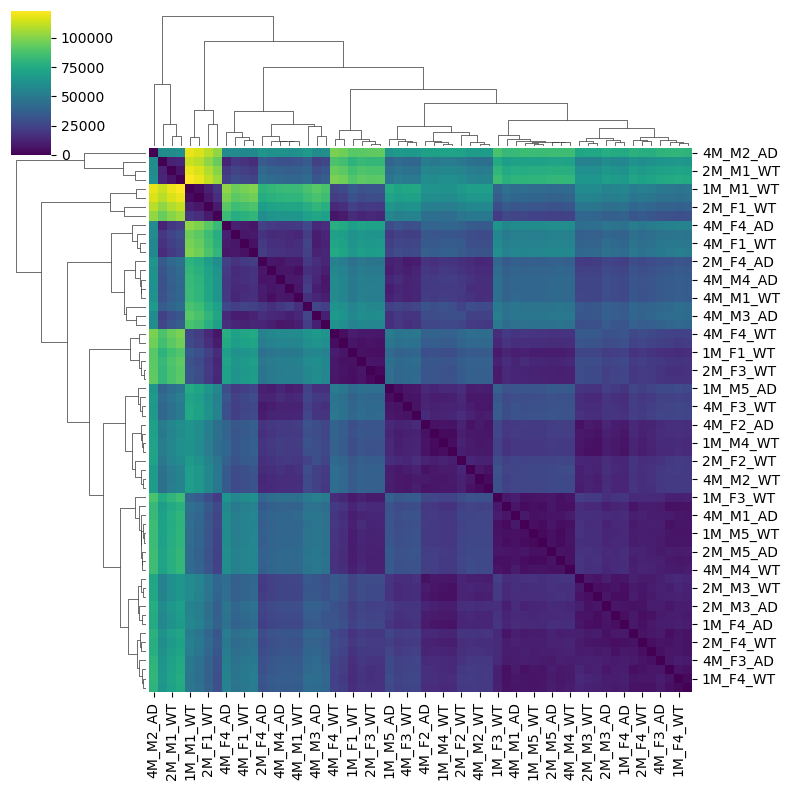

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.clustermap(
    dists_df,
    cmap="viridis",
    method="average",
    z_score=None,
    standard_scale=None,
    figsize=(8, 8)
)

In [17]:
from sklearn.preprocessing import StandardScaler

# log transform and transpose to samples x genes again
X = np.log10(counts_m.to_numpy() + 1.0).T 
sample_names = counts_m.columns.tolist()

# scale features (genes) across samples
scaler = StandardScaler(with_mean=True, with_std=True)
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-1.03733205, -1.84229197, -0.60820428, ..., -0.4151381 ,
         1.12649131, -1.94104111],
       [-0.27309672,  1.46583538,  0.64675206, ...,  0.26649029,
        -0.59167172, -0.00366744],
       [-1.03733205,  0.83548798,  0.55159563, ..., -0.01017223,
        -0.59167172,  0.89064998],
       ...,
       [ 1.0333722 ,  0.94397527,  0.4525542 , ...,  1.0671234 ,
        -0.59167172,  0.77283956],
       [-1.03733205,  1.37905093,  1.27970277, ...,  0.77415681,
        -0.59167172,  0.15736787],
       [-0.27309672, -0.27501275,  0.07011834, ...,  0.65573493,
         1.12649131,  0.23402938]])

In [20]:
sample_ids = list(counts_m.columns)

# create a DataFrame with sample_id
metadata = pd.DataFrame({"sample_id": sample_ids})
metadata
parts = metadata["sample_id"].str.split("_", expand=True)
parts = metadata["sample_id"].str.extract(
    r"^(?P<age>[^_]+)_(?P<bio_rep>[^_]+)_(?P<treatment>[^_]+)$"
)
parts

metadata = pd.concat([metadata, parts], axis=1)
metadata = metadata.set_index("sample_id")
metadata

,age,bio_rep,treatment
sample_id,,,
1M_F1_WT,1M,F1,WT
1M_F2_WT,1M,F2,WT
1M_F3_WT,1M,F3,WT
1M_F4_WT,1M,F4,WT
1M_F5_WT,1M,F5,WT
1M_M1_WT,1M,M1,WT
1M_M2_WT,1M,M2,WT
1M_M3_WT,1M,M3,WT
1M_M4_WT,1M,M4,WT


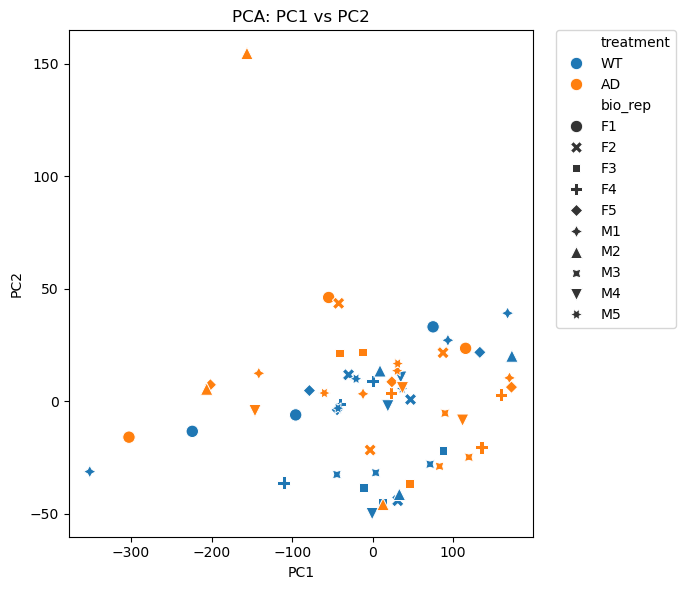

In [21]:

from sklearn.decomposition import PCA

pca = PCA(n_components=10, random_state=0)  
scores = pca.fit_transform(X_scaled)        
# explained = pca.explained_variance_ratio_

scores_df = pd.DataFrame(
    scores[:, :2],  # PC1 and PC2 for plotting
    index=sample_names,
    columns=["PC1", "PC2"]
)

plot_df = scores_df.join(metadata[["treatment", "bio_rep"]], how="left")

# plot
plt.figure(figsize=(7, 6))
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="treatment",     # color by treatment
    style="",     # shape bi bio_rep
    s=80
)
plt.title("PCA: PC1 vs PC2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", borderaxespad=0.)
plt.tight_layout()
plt.show()

## Perform differential expression

Use Python and DESeq2 to perform differential expression analysis on your counts. Generate a volcano plot of the data.

Choose one gene from the paper that was highlighted as being differentially expressed. Compare your data for this gene (raw counts if available, log<sub>2</sub> fold-change, and adjusted p-values) to the data reported in the paper.

Re-generate the PCA plot, now on counts that have had the variance-stabilizing tranformation performed on them.

## Snakemake Pipeline (optional)

1. Copy your `Snakefile` and `config.yaml` from `8_counting` to `9_differential_expression`.  
2. In the `Snakefile`, add the following rules:  
    a. `differential_expression` - write a Python script that performs QC (clustering and PCA) and differential expression. The rule should run the script, and the output should be plots (heatmap, PCA, volcano plot) and a CSV of the DEGs.

This `Snakefile` should not use any `wrappers` because we already have the relevant software installed in the `biol343` conda environment. The pipeline should run to completion when any instructor or classmate runs `snakemake --use-conda`.